In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report, make_scorer)
import warnings
import time
warnings.filterwarnings('ignore')

# ====================================
# PHASE 3: MACHINE LEARNING MODELING WITH HYPERPARAMETER TUNING (25 pts)
# ====================================

print("="*70)
print(" PHASE 3: MACHINE LEARNING MODELING WITH HYPERPARAMETER TUNING")
print("="*70)

In [ ]:
# ====================================
# STEP 1: LOAD PREPROCESSED DATA
# ====================================
print("\n[STEP 1] Loading Preprocessed Data...")

try:
    X_train = pd.read_csv('data/X_train.csv')
    X_test = pd.read_csv('data/X_test.csv')
    y_train = pd.read_csv('data/y_train.csv').values.ravel()
    y_test = pd.read_csv('data/y_test.csv').values.ravel()

    print(f"✅ Data loaded successfully")
    print(f"   Training samples: {X_train.shape[0]}")
    print(f"   Testing samples: {X_test.shape[0]}")
    print(f"   Features: {X_train.shape[1]}")
    print(f"   Target classes: {np.unique(y_train)}")

except FileNotFoundError:
    print("❌ Error: Preprocessed data files not found.")
    print("   Please run Phase 2 preprocessing first!")
    exit()

In [ ]:
# ====================================
# STEP 2: MODEL INITIALIZATION WITH HYPERPARAMETER GRIDS
# ====================================
print("\n" + "="*70)
print("[STEP 2] Defining Models and Hyperparameter Grids...")
print("="*70)

# Define base models and their hyperparameter search spaces
models_config = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {
            'C': [0.01, 0.1, 1, 10, 100],
            'penalty': ['l2'],
            'solver': ['lbfgs', 'liblinear'],
            'class_weight': ['balanced', None]
        }
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': [50, 100, 200],
            'max_depth': [5, 10, 15, None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4],
            'class_weight': ['balanced', 'balanced_subsample', None]
        }
    },
    'Gradient Boosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {
            'n_estimators': [50, 100, 200],
            'learning_rate': [0.01, 0.1, 0.2],
            'max_depth': [3, 5, 7],
            'min_samples_split': [2, 5, 10],
            'subsample': [0.8, 0.9, 1.0]
        }
    },
    'Support Vector Machine': {
        'model': SVC(probability=True, random_state=42),
        'params': {
            'C': [0.1, 1, 10, 100],
            'kernel': ['rbf', 'linear'],
            'gamma': ['scale', 'auto'],
            'class_weight': ['balanced', None]
        }
    }
}

print(f"✅ {len(models_config)} models configured with hyperparameter grids:")
for i, model_name in enumerate(models_config.keys(), 1):
    n_combinations = np.prod([len(v) for v in models_config[model_name]['params'].values()])
    print(f"   {i}. {model_name}: {n_combinations} parameter combinations")

In [ ]:
# ====================================
# STEP 3: BASELINE MODEL TRAINING (DEFAULT PARAMETERS)
# ====================================
print("\n" + "="*70)
print("[STEP 3] Training Baseline Models (Default Parameters)...")
print("="*70)

baseline_models = {}
baseline_results = []

print("Training models with default parameters to establish baseline...")

for model_name, config in models_config.items():
    print(f"\n🔄 Training baseline {model_name}...")

    start_time = time.time()

    # Train with default parameters
    baseline_model = config['model']
    baseline_model.fit(X_train, y_train)

    elapsed_time = time.time() - start_time

    # Make predictions
    y_pred = baseline_model.predict(X_test)
    y_pred_proba = baseline_model.predict_proba(X_test)[:, 1]

    # Calculate metrics
    baseline_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_pred_proba),
        'Training_Time': elapsed_time
    })

    baseline_models[model_name] = baseline_model

    print(f"   ✅ Complete - ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f} (Time: {elapsed_time:.2f}s)")

# Create baseline results DataFrame
baseline_df = pd.DataFrame(baseline_results)
baseline_df = baseline_df.sort_values('ROC-AUC', ascending=False)

print("\n" + "="*70)
print("📊 BASELINE MODEL PERFORMANCE (Default Parameters)")
print("="*70)
print(baseline_df.to_string(index=False))

In [ ]:
# ====================================
# STEP 4: HYPERPARAMETER TUNING WITH GRIDSEARCHCV
# ====================================
print("\n" + "="*70)
print("[STEP 4] Hyperparameter Tuning (GridSearchCV with 5-Fold CV)...")
print("="*70)

print("Now optimizing each model to improve upon baseline performance...\n")

trained_models = {}
tuning_results = []
best_params_dict = {}

# Custom scoring metric (prioritize ROC-AUC)
scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc'
}

for model_name, config in models_config.items():
    print(f"\n{'='*70}")
    print(f"🔄 Tuning {model_name}...")
    print(f"{'='*70}")

    start_time = time.time()

    # GridSearchCV with 5-fold cross-validation
    grid_search = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        scoring='roc_auc',  # Optimize for ROC-AUC
        cv=5,
        n_jobs=-1,
        verbose=1,
        return_train_score=True
    )

    # Fit the grid search
    grid_search.fit(X_train, y_train)

    elapsed_time = time.time() - start_time

    # Store best model
    trained_models[model_name] = grid_search.best_estimator_
    best_params_dict[model_name] = grid_search.best_params_

    # Store tuning results
    tuning_results.append({
        'Model': model_name,
        'Baseline_ROC_AUC': baseline_df[baseline_df['Model'] == model_name]['ROC-AUC'].values[0],
        'Tuned_ROC_AUC': grid_search.best_score_,
        'Improvement': grid_search.best_score_ - baseline_df[baseline_df['Model'] == model_name]['ROC-AUC'].values[0],
        'Mean_Fit_Time': grid_search.cv_results_['mean_fit_time'].mean(),
        'Tuning_Time': elapsed_time
    })

    print(f"\n✅ {model_name} tuning complete!")
    print(f"   Best CV ROC-AUC: {grid_search.best_score_:.4f}")
    print(f"   Tuning time: {elapsed_time:.2f} seconds")
    print(f"\n   Best Parameters:")
    for param, value in grid_search.best_params_.items():
        print(f"      {param}: {value}")

# Display tuning summary with improvement
print("\n" + "="*70)
print("📊 HYPERPARAMETER TUNING SUMMARY - BASELINE vs TUNED")
print("="*70)
tuning_df = pd.DataFrame(tuning_results)
print(tuning_df.to_string(index=False))

print("\n💡 Key Insights:")
for idx, row in tuning_df.iterrows():
    improvement_pct = (row['Improvement'] / row['Baseline_ROC_AUC']) * 100
    if row['Improvement'] > 0:
        print(f"   ✅ {row['Model']}: +{row['Improvement']:.4f} ROC-AUC ({improvement_pct:+.2f}% improvement)")
    else:
        print(f"   ⚠️ {row['Model']}: {row['Improvement']:.4f} ROC-AUC ({improvement_pct:.2f}% change)")

In [ ]:
# ====================================
# STEP 5: MODEL EVALUATION ON TEST SET (TUNED MODELS)
# ====================================
print("\n" + "="*70)
print("[STEP 5] Evaluating Tuned Models on Test Set (5 Metrics)...")
print("="*70)

results = []

for model_name, model in trained_models.items():
    print(f"\n📊 Evaluating {model_name}...")

    # Make predictions
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    # Calculate 5 required metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    # Store results
    results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    })

    print(f"   Accuracy:  {accuracy:.4f}")
    print(f"   Precision: {precision:.4f}")
    print(f"   Recall:    {recall:.4f}")
    print(f"   F1-Score:  {f1:.4f}")
    print(f"   ROC-AUC:   {roc_auc:.4f}")

# Create results DataFrame
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('ROC-AUC', ascending=False)

print("\n" + "="*70)
print("📊 TUNED MODEL COMPARISON (Sorted by ROC-AUC)")
print("="*70)
print(results_df.to_string(index=False))

# Compare with baseline
print("\n" + "="*70)
print("📈 BASELINE vs TUNED PERFORMANCE COMPARISON")
print("="*70)
comparison_df = baseline_df[['Model', 'ROC-AUC']].merge(
    results_df[['Model', 'ROC-AUC']],
    on='Model',
    suffixes=('_Baseline', '_Tuned')
)
comparison_df['Improvement'] = comparison_df['ROC-AUC_Tuned'] - comparison_df['ROC-AUC_Baseline']
comparison_df['Improvement_%'] = (comparison_df['Improvement'] / comparison_df['ROC-AUC_Baseline'] * 100)
print(comparison_df.to_string(index=False))

# Identify best model
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
print(f"\n🏆 BEST MODEL: {best_model_name}")
print(f"   Baseline ROC-AUC: {baseline_df[baseline_df['Model'] == best_model_name]['ROC-AUC'].values[0]:.4f}")
print(f"   Tuned ROC-AUC: {results_df.iloc[0]['ROC-AUC']:.4f}")
print(f"   Improvement: +{results_df.iloc[0]['ROC-AUC'] - baseline_df[baseline_df['Model'] == best_model_name]['ROC-AUC'].values[0]:.4f}")

In [ ]:
# ====================================
# STEP 6: CROSS-VALIDATION SCORES
# ====================================
print("\n" + "="*70)
print("[STEP 6] Cross-Validation Analysis (Best Model)...")
print("="*70)

cv_scores = cross_val_score(best_model, X_train, y_train, cv=5, scoring='roc_auc')
print(f"\n{best_model_name} - 5-Fold CV Scores:")
for i, score in enumerate(cv_scores, 1):
    print(f"   Fold {i}: {score:.4f}")
print(f"\n   Mean CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

In [ ]:
# ====================================
# STEP 7: DETAILED CLASSIFICATION REPORT
# ====================================
print("\n" + "="*70)
print("[STEP 7] Detailed Classification Report (Best Model)")
print("="*70)

y_pred_best = best_model.predict(X_test)
print(f"\n{best_model_name} - Classification Report:")
print(classification_report(y_test, y_pred_best, target_names=['No Attrition', 'Attrition']))

In [ ]:
# ====================================
# STEP 8: FEATURE IMPORTANCE (for tree-based models)
# ====================================
print("\n" + "="*70)
print("[STEP 8] Feature Importance Analysis...")
print("="*70)

feature_importance_data = {}

for model_name, model in trained_models.items():
    if hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
        feature_importance_data[model_name] = pd.DataFrame({
            'Feature': X_train.columns,
            'Importance': importances
        }).sort_values('Importance', ascending=False).head(15)

        print(f"\n✅ {model_name} - Top 10 Features:")
        for idx, row in feature_importance_data[model_name].head(10).iterrows():
            print(f"   {row['Feature']}: {row['Importance']:.4f}")
    elif hasattr(model, 'coef_'):
        # For Logistic Regression
        importances = np.abs(model.coef_[0])
        feature_importance_data[model_name] = pd.DataFrame({
            'Feature': X_train.columns,
            'Importance': importances
        }).sort_values('Importance', ascending=False).head(15)

        print(f"\n✅ {model_name} - Top 10 Features (Coefficient Magnitude):")
        for idx, row in feature_importance_data[model_name].head(10).iterrows():
            print(f"   {row['Feature']}: {row['Importance']:.4f}")

In [ ]:
# ====================================
# STEP 9: VISUALIZATION DASHBOARD
# ====================================
print("\n" + "="*70)
print("[STEP 9] Generating Comprehensive Visualization Dashboard...")
print("="*70)

fig = plt.figure(figsize=(22, 18))
gs = fig.add_gridspec(6, 3, hspace=0.4, wspace=0.3)

# 9.1 Baseline vs Tuned Performance Comparison
ax1 = fig.add_subplot(gs[0, :])
x_pos = np.arange(len(comparison_df))
width = 0.35

bars1 = ax1.bar(x_pos - width/2, comparison_df['ROC-AUC_Baseline'], width,
                label='Baseline', color='#e74c3c', edgecolor='black', linewidth=1.5)
bars2 = ax1.bar(x_pos + width/2, comparison_df['ROC-AUC_Tuned'], width,
                label='Tuned', color='#2ecc71', edgecolor='black', linewidth=1.5)

ax1.set_xlabel('Models', fontsize=12, fontweight='bold')
ax1.set_ylabel('ROC-AUC Score', fontsize=12, fontweight='bold')
ax1.set_title('Baseline vs Hyperparameter-Tuned Performance Comparison',
              fontsize=14, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(comparison_df['Model'], rotation=15, ha='right')
ax1.legend(loc='lower right', fontsize=11)
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim([comparison_df['ROC-AUC_Baseline'].min() - 0.05, 1.0])

# Add improvement annotations
for i, (bar1, bar2, improvement) in enumerate(zip(bars1, bars2, comparison_df['Improvement'])):
    if improvement > 0:
        ax1.annotate(f'+{improvement:.3f}',
                    xy=(bar2.get_x() + bar2.get_width()/2, bar2.get_height()),
                    xytext=(0, 5), textcoords='offset points',
                    ha='center', fontweight='bold', color='green', fontsize=9)

# 9.2 Tuned Model Performance Comparison (All Metrics)
ax2 = fig.add_subplot(gs[1, :])
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
x = np.arange(len(results_df))
width = 0.15

for i, metric in enumerate(metrics):
    offset = width * (i - 2)
    bars = ax2.bar(x + offset, results_df[metric], width, label=metric)

ax2.set_xlabel('Models', fontsize=12, fontweight='bold')
ax2.set_ylabel('Score', fontsize=12, fontweight='bold')
ax2.set_title('Tuned Model Performance - All Metrics', fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(results_df['Model'], rotation=15, ha='right')
ax2.legend(loc='lower right', ncol=5)
ax2.grid(axis='y', alpha=0.3)
ax2.set_ylim([0, 1.05])

# 9.3 Improvement Percentage
ax3 = fig.add_subplot(gs[2, 0])
colors_improvement = ['#2ecc71' if x > 0 else '#e74c3c' for x in comparison_df['Improvement_%']]
bars = ax3.barh(comparison_df['Model'], comparison_df['Improvement_%'],
                color=colors_improvement, edgecolor='black', linewidth=1.5)
ax3.set_xlabel('Improvement (%)', fontsize=11, fontweight='bold')
ax3.set_title('Performance Improvement\nFrom Tuning', fontsize=12, fontweight='bold')
ax3.axvline(0, color='black', linestyle='-', linewidth=2)
ax3.grid(axis='x', alpha=0.3)
for bar, val in zip(bars, comparison_df['Improvement_%']):
    label_x = val + (0.2 if val > 0 else -0.2)
    ax3.text(label_x, bar.get_y() + bar.get_height()/2,
            f'{val:+.1f}%', va='center', fontweight='bold', fontsize=9)

# 9.4 Tuning Time vs Improvement
ax4 = fig.add_subplot(gs[2, 1])
scatter = ax4.scatter(tuning_df['Tuning_Time'], tuning_df['Improvement'],
                     s=200, c=tuning_df['Improvement'], cmap='RdYlGn',
                     edgecolors='black', linewidth=2, alpha=0.7, vmin=-0.01, vmax=0.05)
for idx, row in tuning_df.iterrows():
    ax4.annotate(row['Model'].split()[0],
                (row['Tuning_Time'], row['Improvement']),
                fontsize=8, ha='center', va='bottom')
ax4.set_xlabel('Tuning Time (seconds)', fontsize=11, fontweight='bold')
ax4.set_ylabel('ROC-AUC Improvement', fontsize=11, fontweight='bold')
ax4.set_title('Tuning Efficiency:\nTime vs Improvement', fontsize=12, fontweight='bold')
ax4.axhline(0, color='red', linestyle='--', linewidth=2, label='No Improvement')
ax4.grid(alpha=0.3)
ax4.legend()
plt.colorbar(scatter, ax=ax4, label='Improvement')

# 9.5 CV Score Distribution (Best Model)
ax5 = fig.add_subplot(gs[2, 2])
ax5.bar(range(1, 6), cv_scores, color='#3498db', edgecolor='black', linewidth=2)
ax5.axhline(cv_scores.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {cv_scores.mean():.3f}')
ax5.set_xlabel('Fold', fontsize=11, fontweight='bold')
ax5.set_ylabel('ROC-AUC Score', fontsize=11, fontweight='bold')
ax5.set_title(f'CV Stability\n{best_model_name}', fontsize=12, fontweight='bold')
ax5.set_xticks(range(1, 6))
ax5.legend()
ax5.grid(axis='y', alpha=0.3)

# 9.6 Best Parameters Comparison
ax6 = fig.add_subplot(gs[3, 0])
param_text = "🏆 OPTIMAL HYPERPARAMETERS\n\n"
for model_name, params in best_params_dict.items():
    param_text += f"{model_name}:\n"
    for param, value in params.items():
        param_text += f"  • {param}: {value}\n"
    param_text += "\n"
ax6.text(0.05, 0.95, param_text, transform=ax6.transAxes,
        fontsize=9, verticalalignment='top', fontfamily='monospace',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax6.axis('off')

# 9.7 ROC Curves for All Tuned Models
ax7 = fig.add_subplot(gs[3, 1:])
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

for idx, (model_name, model) in enumerate(trained_models.items()):
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    auc = roc_auc_score(y_test, y_pred_proba)
    ax7.plot(fpr, tpr, label=f'{model_name} (AUC={auc:.3f})',
             linewidth=2.5, color=colors[idx])

ax7.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
ax7.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
ax7.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
ax7.set_title('ROC Curves - Tuned Models Comparison', fontsize=14, fontweight='bold')
ax7.legend(loc='lower right')
ax7.grid(alpha=0.3)

# 9.8 Best Model ROC Curve (Highlighted)
ax8 = fig.add_subplot(gs[4, 0])
y_pred_proba_best = best_model.predict_proba(X_test)[:, 1]
fpr_best, tpr_best, thresholds = roc_curve(y_test, y_pred_proba_best)
auc_best = roc_auc_score(y_test, y_pred_proba_best)

ax8.plot(fpr_best, tpr_best, linewidth=3, color='#2ecc71', label=f'AUC={auc_best:.3f}')
ax8.fill_between(fpr_best, tpr_best, alpha=0.3, color='#2ecc71')
ax8.plot([0, 1], [0, 1], 'k--', linewidth=2)

# Find optimal threshold (Youden's J statistic)
j_scores = tpr_best - fpr_best
optimal_idx = np.argmax(j_scores)
optimal_threshold = thresholds[optimal_idx]
ax8.plot(fpr_best[optimal_idx], tpr_best[optimal_idx], 'ro', markersize=10,
         label=f'Optimal: {optimal_threshold:.3f}')

ax8.set_xlabel('False Positive Rate', fontsize=11, fontweight='bold')
ax8.set_ylabel('True Positive Rate', fontsize=11, fontweight='bold')
ax8.set_title(f'🏆 Best Model ROC\n{best_model_name}', fontsize=12, fontweight='bold')
ax8.legend(loc='lower right')
ax8.grid(alpha=0.3)

# 9.9-9.12 Confusion Matrices for All Models
for idx, (model_name, model) in enumerate(trained_models.items()):
    row = 4 + (idx // 2)
    col = 1 + (idx % 2)
    ax = fig.add_subplot(gs[row, col])

    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                cbar_kws={'label': 'Count'}, linewidths=1, linecolor='black')
    ax.set_xlabel('Predicted', fontsize=10, fontweight='bold')
    ax.set_ylabel('Actual', fontsize=10, fontweight='bold')
    ax.set_title(f'{model_name}', fontsize=11, fontweight='bold')
    ax.set_xticklabels(['No', 'Yes'])
    ax.set_yticklabels(['No', 'Yes'])

plt.suptitle('PHASE 3: BASELINE vs HYPERPARAMETER-TUNED MODEL EVALUATION',
             fontsize=18, fontweight='bold', y=0.998)
plt.savefig('phase3_model_evaluation_tuned.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Visualization saved: 'phase3_model_evaluation_tuned.png'")

In [ ]:
# ====================================
# STEP 10: SAVE MODEL RESULTS
# ====================================
print("\n" + "="*70)
print("[STEP 10] Saving Model Results and Best Parameters...")
print("="*70)

# Save baseline results
baseline_df.to_csv('data/baseline_model_comparison.csv', index=False)
print("✅ Saved: 'baseline_model_comparison.csv'")

# Save tuned model comparison results
results_df.to_csv('data/model_comparison.csv', index=False)
print("✅ Saved: 'model_comparison.csv'")

# Save baseline vs tuned comparison
comparison_df.to_csv('data/baseline_vs_tuned_comparison.csv', index=False)
print("✅ Saved: 'baseline_vs_tuned_comparison.csv'")

# Save tuning results
tuning_df.to_csv('data/hyperparameter_tuning_results.csv', index=False)
print("✅ Saved: 'hyperparameter_tuning_results.csv'")

# Save best parameters
best_params_df = pd.DataFrame([
    {'Model': model, 'Parameter': param, 'Value': value}
    for model, params in best_params_dict.items()
    for param, value in params.items()
])
best_params_df.to_csv('data/best_hyperparameters.csv', index=False)
print("✅ Saved: 'best_hyperparameters.csv'")

# Save best model predictions
best_predictions = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_best,
    'Probability': y_pred_proba_best
})
best_predictions.to_csv('data/best_model_predictions.csv', index=False)
print("✅ Saved: 'best_model_predictions.csv'")

# Save feature importance
if best_model_name in feature_importance_data:
    feature_importance_data[best_model_name].to_csv('data/feature_importance.csv', index=False)
    print("✅ Saved: 'feature_importance.csv'")

# Save model object (using joblib for better compatibility)
import joblib
joblib.dump(best_model, 'data/best_model.pkl')
print("✅ Saved: 'best_model.pkl' (for Streamlit deployment)")

# Also save the scaler info and feature names for Phase 5
model_metadata = {
    'best_model_name': best_model_name,
    'best_params': best_params_dict[best_model_name],
    'feature_names': X_train.columns.tolist(),
    'n_features': X_train.shape[1],
    'metrics': results_df.iloc[0].to_dict(),
    'cv_scores': cv_scores.tolist(),
    'optimal_threshold': float(optimal_threshold)
}
joblib.dump(model_metadata, 'data/model_metadata.pkl')
print("✅ Saved: 'model_metadata.pkl' (metadata for deployment)")


In [ ]:
# ====================================
# STEP 11: MODEL IMPROVEMENT ANALYSIS
# ====================================
print("\n" + "="*70)
print("[STEP 11] Analyzing Hyperparameter Tuning Impact...")
print("="*70)

print("\n📊 Performance Improvement Summary:")
print(f"   Best Model: {best_model_name}")
print(f"   Baseline ROC-AUC: {baseline_df[baseline_df['Model'] == best_model_name]['ROC-AUC'].values[0]:.4f}")
print(f"   Tuned ROC-AUC: {results_df.iloc[0]['ROC-AUC']:.4f}")
improvement = results_df.iloc[0]['ROC-AUC'] - baseline_df[baseline_df['Model'] == best_model_name]['ROC-AUC'].values[0]
improvement_pct = (improvement / baseline_df[baseline_df['Model'] == best_model_name]['ROC-AUC'].values[0]) * 100
print(f"   Absolute Improvement: +{improvement:.4f}")
print(f"   Relative Improvement: +{improvement_pct:.2f}%")
print(f"   CV ROC-AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")
print(f"   Optimal Decision Threshold: {optimal_threshold:.3f}")

# Calculate metrics at optimal threshold
y_pred_optimal = (y_pred_proba_best >= optimal_threshold).astype(int)
cm_optimal = confusion_matrix(y_test, y_pred_optimal)
tn, fp, fn, tp = cm_optimal.ravel()

print(f"\n📈 Performance at Optimal Threshold:")
print(f"   True Negatives:  {tn}")
print(f"   False Positives: {fp}")
print(f"   False Negatives: {fn}")
print(f"   True Positives:  {tp}")
print(f"   Specificity:     {tn/(tn+fp):.4f}")
print(f"   Sensitivity:     {tp/(tp+fn):.4f}")

 PHASE 3: MACHINE LEARNING MODELING WITH HYPERPARAMETER TUNING

[STEP 1] Loading Preprocessed Data...
✅ Data loaded successfully
   Training samples: 559
   Testing samples: 140
   Features: 53
   Target classes: [0 1]

[STEP 2] Defining Models and Hyperparameter Grids...
✅ 4 models configured with hyperparameter grids:
   1. Logistic Regression: 20 parameter combinations
   2. Random Forest: 324 parameter combinations
   3. Gradient Boosting: 243 parameter combinations
   4. Support Vector Machine: 32 parameter combinations

[STEP 3] Training Baseline Models (Default Parameters)...
Training models with default parameters to establish baseline...

🔄 Training baseline Logistic Regression...
   ✅ Complete - ROC-AUC: 0.8481 (Time: 0.14s)

🔄 Training baseline Random Forest...
   ✅ Complete - ROC-AUC: 0.7924 (Time: 0.54s)

🔄 Training baseline Gradient Boosting...
   ✅ Complete - ROC-AUC: 0.8057 (Time: 0.99s)

🔄 Training baseline Support Vector Machine...
   ✅ Complete - ROC-AUC: 0.8071 (Tim


✅ Random Forest - Top 10 Features:
   Age: 0.0696
   MonthlyIncome: 0.0682
   AvgYearsPerCompany: 0.0476
   CommuteStress: 0.0444
   TenureRatio: 0.0435
   TotalWorkingYears: 0.0435
   IncomePerAge: 0.0421
   HourlyRate: 0.0411
   DailyRate: 0.0380
   EmployeeNumber: 0.0373

✅ Gradient Boosting - Top 10 Features:
   MonthlyIncome: 0.1012
   CommuteStress: 0.0776
   Age: 0.0593
   OverTime: 0.0542
   HourlyRate: 0.0489
   StockOptionLevel: 0.0455
   DailyRate: 0.0435
   EmployeeNumber: 0.0429
   JobInvolvement: 0.0417
   EnvironmentSatisfaction: 0.0406

✅ Support Vector Machine - Top 10 Features (Coefficient Magnitude):
   OverTime: 0.4931
   StockOptionLevel: 0.4883
   BusinessTravel_Travel_Frequently: 0.4789
   EnvironmentSatisfaction: 0.3639
   TotalWorkingYears: 0.3635
   CommuteStress: 0.3285
   NumCompaniesWorked: 0.2944
   Age: 0.2847
   IncomePerAge: 0.2816
   RelationshipSatisfaction: 0.2489

[STEP 9] Generating Comprehensive Visualization Dashboard...


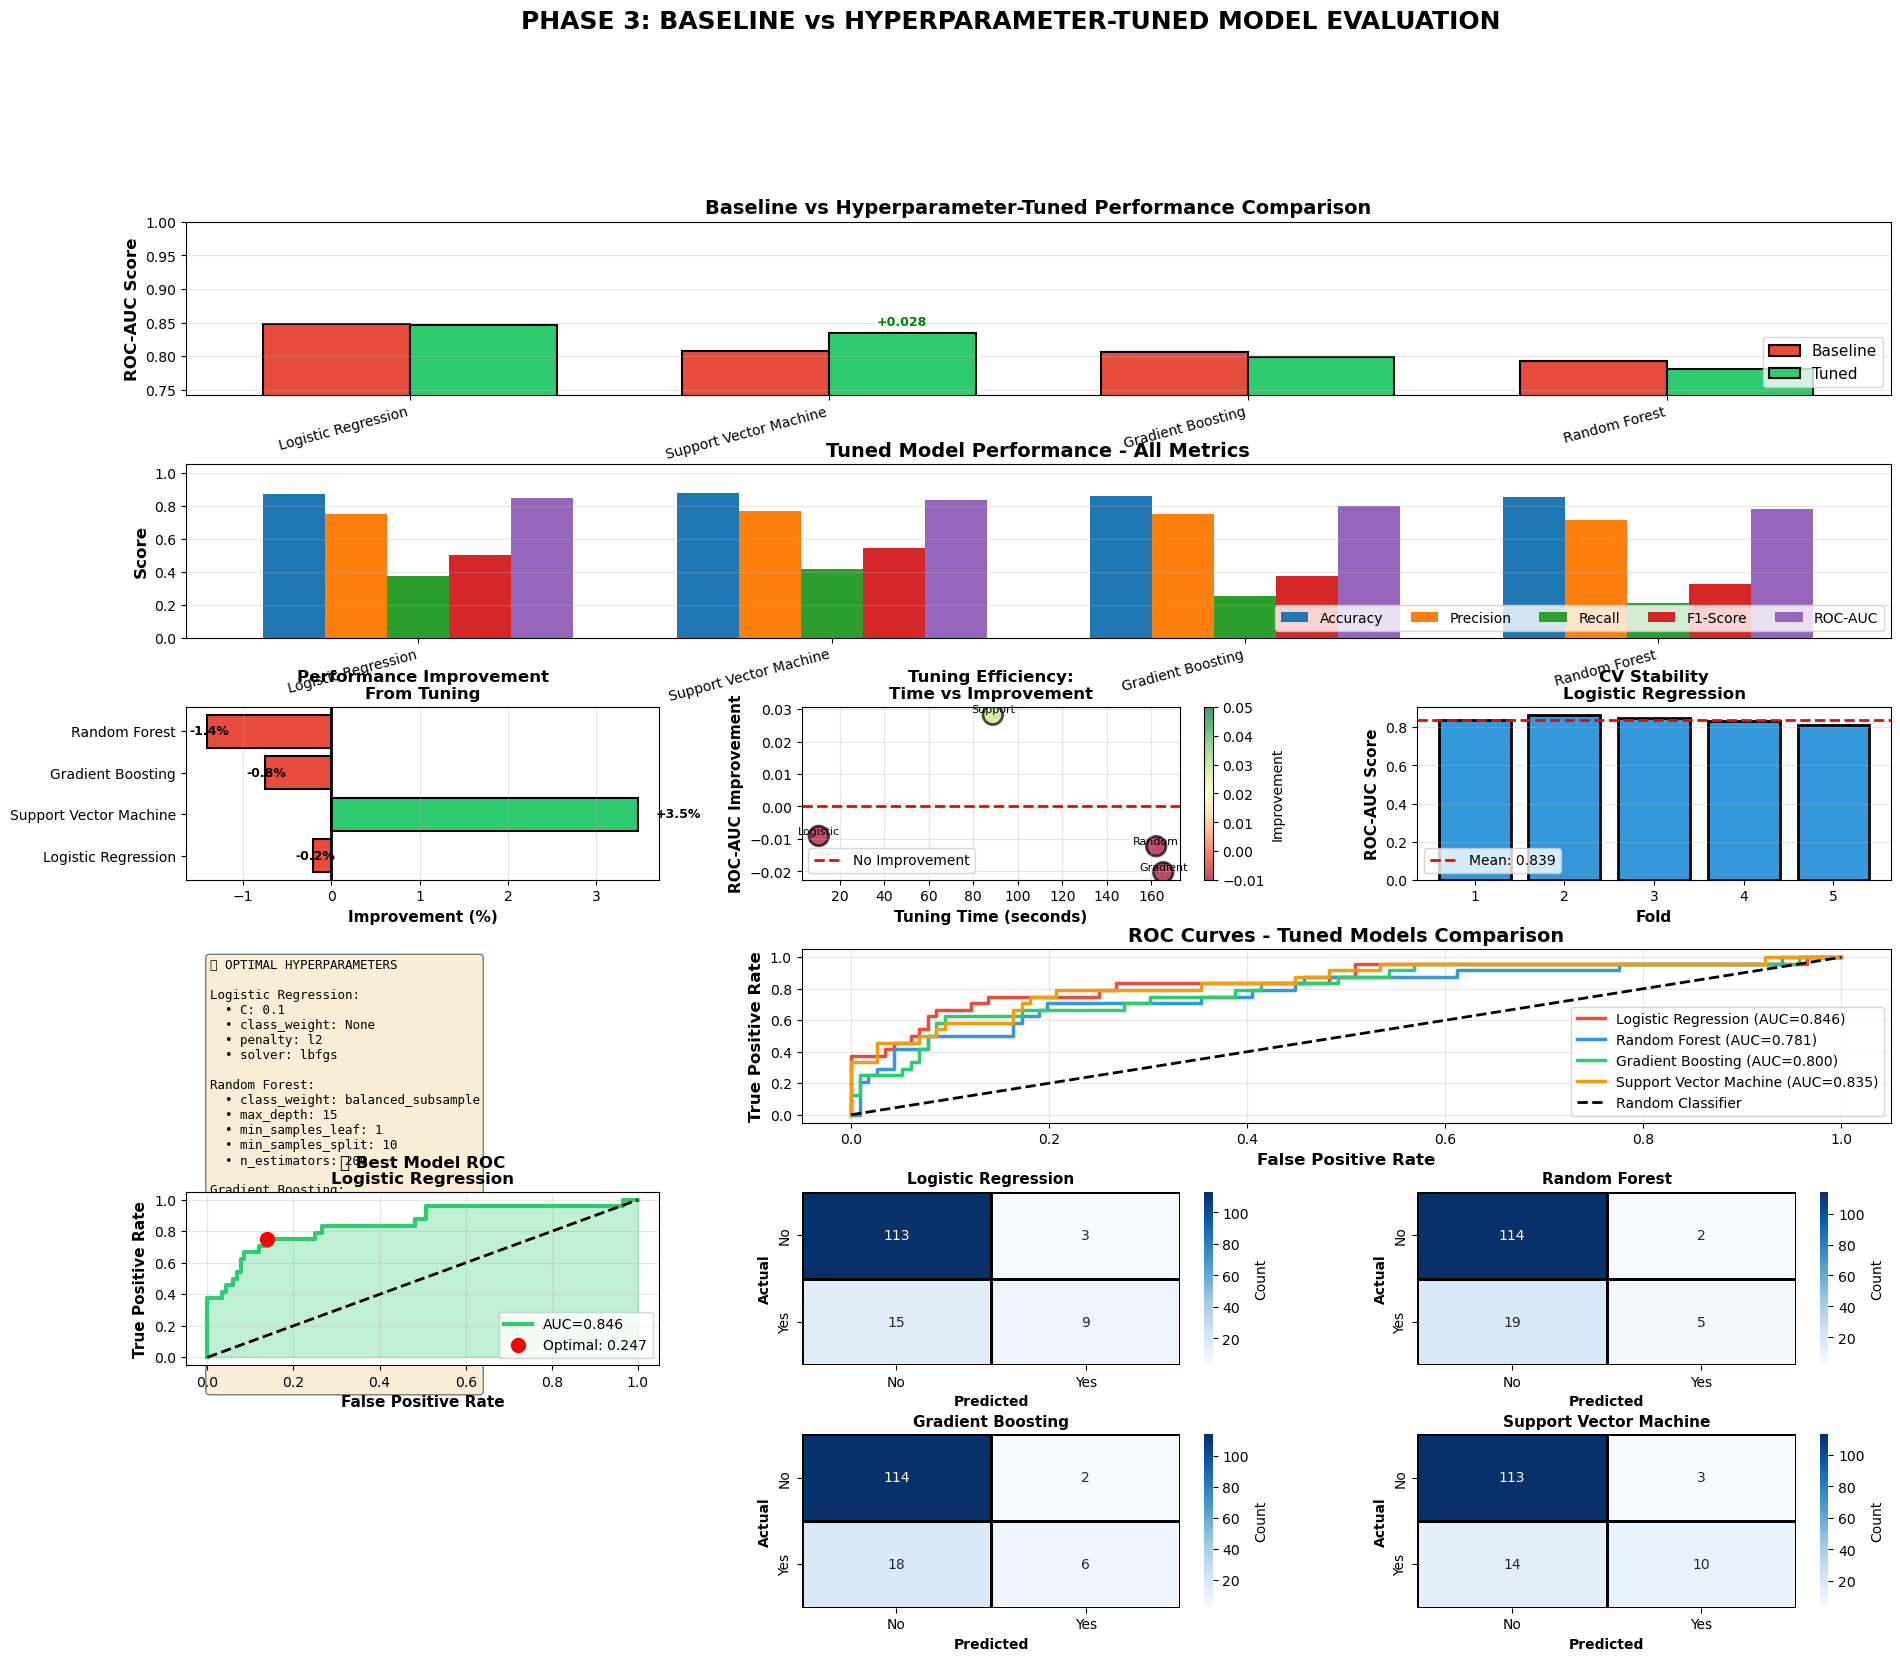

✅ Visualization saved: 'phase3_model_evaluation_tuned.png'

[STEP 10] Saving Model Results and Best Parameters...
✅ Saved: 'baseline_model_comparison.csv'
✅ Saved: 'model_comparison.csv'
✅ Saved: 'baseline_vs_tuned_comparison.csv'
✅ Saved: 'hyperparameter_tuning_results.csv'
✅ Saved: 'best_hyperparameters.csv'
✅ Saved: 'best_model_predictions.csv'
✅ Saved: 'feature_importance.csv'
✅ Saved: 'best_model.pkl' (for Streamlit deployment)
✅ Saved: 'model_metadata.pkl' (metadata for deployment)

[STEP 11] Analyzing Hyperparameter Tuning Impact...

📊 Performance Improvement Summary:
   Best Model: Logistic Regression
   Baseline ROC-AUC: 0.8481
   Tuned ROC-AUC: 0.8463
   Absolute Improvement: +-0.0018
   Relative Improvement: +-0.21%
   CV ROC-AUC: 0.8390 (+/- 0.0344)
   Optimal Decision Threshold: 0.247

📈 Performance at Optimal Threshold:
   True Negatives:  100
   False Positives: 16
   False Negatives: 6
   True Positives:  18
   Specificity:     0.8621
   Sensitivity:     0.7500

✅ PHASE

In [1]:
# ====================================
# FINAL SUMMARY
# ====================================
print("\n" + "="*70)
print("✅ PHASE 3 COMPLETE - HYPERPARAMETER-TUNED MODELING SUMMARY")
print("="*70)

print(f"""
🤖 MODELS TRAINED: {len(trained_models)}
   ✅ Step 1: Baseline models with default parameters
   ✅ Step 2: Hyperparameter tuning with GridSearchCV
   
   • Logistic Regression (Grid: {np.prod([len(v) for v in models_config['Logistic Regression']['params'].values()])} combinations)
   • Random Forest (Grid: {np.prod([len(v) for v in models_config['Random Forest']['params'].values()])} combinations)
   • Gradient Boosting (Grid: {np.prod([len(v) for v in models_config['Gradient Boosting']['params'].values()])} combinations)
   • Support Vector Machine (Grid: {np.prod([len(v) for v in models_config['Support Vector Machine']['params'].values()])} combinations)

📊 EVALUATION METRICS (5 Required):
   ✅ Accuracy
   ✅ Precision
   ✅ Recall
   ✅ F1-Score
   ✅ ROC-AUC

🏆 BEST PERFORMING MODEL (AFTER TUNING):
   Model: {best_model_name}
   Baseline ROC-AUC: {baseline_df[baseline_df['Model'] == best_model_name]['ROC-AUC'].values[0]:.4f}
   Tuned ROC-AUC: {results_df.iloc[0]['ROC-AUC']:.4f}
   Improvement: +{improvement:.4f} (+{improvement_pct:.2f}%)
   
   Optimal Hyperparameters:
""")
for param, value in best_params_dict[best_model_name].items():
    print(f"      • {param}: {value}")

print(f"""
📈 ADVANCED ANALYSIS:
   • Baseline model training (default parameters)
   • 5-Fold Cross-Validation
   • GridSearchCV hyperparameter optimization  
   • Baseline vs Tuned performance comparison
   • Optimal threshold calculation (Youden's J)
   • Training time analysis
   • Model stability assessment

💾 FILES SAVED FOR PHASE 5:
   • baseline_model_comparison.csv (default parameters performance)
   • model_comparison.csv (tuned model performance)
   • baseline_vs_tuned_comparison.csv (improvement analysis)
   • hyperparameter_tuning_results.csv (tuning details)
   • best_hyperparameters.csv (optimal parameters)
   • best_model.pkl (trained & tuned model)
   • model_metadata.pkl (deployment info + optimal threshold)
   • feature_importance.csv (top features)
""")

if best_model_name in feature_importance_data:
    print("🎯 TOP 3 PREDICTIVE FEATURES:")
    for idx, row in feature_importance_data[best_model_name].head(3).iterrows():
        print(f"      {idx+1}. {row['Feature']}: {row['Importance']:.4f}")

print("\n" + "="*70)
print("🚀 Ready for PHASE 4: VISUALIZATION & ANALYSIS")
print("="*70)